# Question 2 (Day 5, Set 1)

## Problem Statement

The following non-uniformly spaced data set is given:

| $x$    | 0 | 1  | 2  | 4 | 5 | 6  |
|--------|---|----|----|---|---|----|
| $F(x)$ | 1 | 14 | 15 | 5 | 6 | 19 |

Evaluate the integral $\displaystyle\int_0^6 f(x)\,dx$ and $\dfrac{dy}{dx}$ at $x = 3$.

Use Newton's divided difference formula for polynomial approximation and the trapezoidal rule to evaluate the integral.


## Analysis and Inputs

- The node at $x = 3$ is missing, so we first need a continuous approximating function before we can evaluate $F(3)$, $\left.\frac{dy}{dx}\right|_{x=3}$, or the definite integral.
- Newton's divided difference formula builds an explicit polynomial $P(x)$ through all six given points without requiring equal spacing, using the divided-difference table $f[x_0], f[x_0,x_1], f[x_0,x_1,x_2], \dots$ as the coefficients of the nested form
$$
P(x) = f[x_0] + f[x_0,x_1](x-x_0) + f[x_0,x_1,x_2](x-x_0)(x-x_1) + \cdots
$$
- Once $P(x)$ is available as a MATLAB function handle:
  - $\left.\dfrac{dy}{dx}\right|_{x=3}$ is estimated with a central-difference formula, refined by halving the step size $h$ until successive estimates agree to within a tolerance $\epsilon$.
  - The integral $\int_0^6 P(x)\,dx$ is estimated with the composite trapezoidal rule applied to $P(x)$, refined by doubling the number of subintervals $m$ until successive estimates agree to within $\epsilon$.
- Convergence is controlled by a tolerance $\epsilon$ and a maximum iteration count $N_{max}$, taken here as $\epsilon = 10^{-6}$ and $N_{max} = 50$.


\newpage

## Algorithm

- **Step 01.** **START**
- **Step 02.** Inputs:

| Variable | Description |
|---|---|
| $x_i, y_i$ | Discrete data coordinates, $i = 1, \dots, 6$ |
| $\epsilon$ | Convergence tolerance |
| $N_{max}$ | Maximum number of iterations |

- **Step 03.** Build the divided-difference table $F$, where $F(i,1) = y_i$ and $F(i,j) = \dfrac{F(i+1,j-1) - F(i,j-1)}{x_{i+j-1} - x_i}$ for $j = 2,\dots,n$.
- **Step 04.** Form the interpolant $P(x) = F(1,1) + \sum_{j=2}^{n} F(1,j)\prod_{i=1}^{j-1}(x - x_i)$, algebraically simplify it, and convert it into a numerical function handle.
- **Step 05.** Approximate the missing value at $x = 3$ as $y_3 = P(3)$.
- **Step 06.** Repeat until $\left|P'_k - P'_{k-1}\right| < \epsilon$ or $k \ge N_{max}$:
  - Estimate $P'(3) \approx \dfrac{P(3+h) - P(3-h)}{2h}$
  - Halve the step size, $h \leftarrow h/2$
- **Step 07.** Repeat until $|I_k - I_{k-1}| < \epsilon$ or iteration count exceeds $N_{max}$:
  - Discretize $[0, 6]$ into $m$ uniform subintervals of width $h = (b-a)/m$ (starting at $m = 6$)
  - Compute $I \approx \dfrac{h}{2}\left[P(x_0) + 2\sum_{i=1}^{m-1} P(x_i) + P(x_m)\right]$
  - Double the interval count, $m \leftarrow 2m$
- **Step 08.** Outputs:

| Variable | Description |
|---|---|
| $P(x)$ | Converged Newton divided-difference interpolating polynomial |
| $y_3$ | Interpolated value at $x = 3$ |
| $\left.dy/dx\right\vert_{x=3}$ | Local derivative at $x = 3$ |
| $I$ | Definite integral over $[0, 6]$ |

- **Step 09.** **STOP**


\newpage

## Implementation

In [1]:
%%file newton_divdiff.m
function [P_sym, P_fun, coeffs] = ...
    newton_divdiff(x_data, y_data) %#ok<FNDEF>
    n = length(x_data);
    F = zeros(n, n);
    F(:, 1) = y_data(:);

    for j = 2:n
        for i = 1:n-j+1
            F(i, j) = ...
            (F(i+1, j-1) - F(i, j-1)) / (x_data(i+j-1) - x_data(i));
        end
    end

    disp(F);

    coeffs = F(1, :);

    syms x
    P_sym = coeffs(1);
    term = sym(1);

    for i = 2:n
        term = term * (x - x_data(i-1));
        P_sym = P_sym + coeffs(i) * term;
    end

    P_sym = simplify(P_sym);
    P_fun = matlabFunction(P_sym);
end


File newton_divdiff.m created successfully.

In [ ]:
%%file central_diff_converge.m
function [dydx, iters] = ...
    central_diff_converge(P_fun, x_target, epsilon, k_max) %#ok<FNDEF>
    h = 0.1;
    dydx = (P_fun(x_target + h) - P_fun(x_target - h)) / (2 * h);
    iters = 0;

    while iters < k_max
        iters = iters + 1;
        dydx_prev = dydx;
        h = h / 2;
        dydx = (P_fun(x_target + h) - P_fun(x_target - h)) / (2 * h);

        if abs(dydx - dydx_prev) < epsilon
            break;
        end
    end
end


File central_diff_converge.m created successfully.

In [15]:
%%file trapezoid_converge.m
function [I, iters, m] = ...
    trapezoid_converge(P_fun, a, b, epsilon, k_max) %#ok<FNDEF>
    m = 6;
    I_prev = 0;
    I = 0;
    iters = 0;

    while iters < k_max
        iters = iters + 1;
        h = (b - a) / m;
        x_nodes = linspace(a, b, m + 1);
        y_nodes = P_fun(x_nodes);

        I = (h / 2) * (y_nodes(1) + 2 * sum(y_nodes(2:end-1))...
            + y_nodes(end));

        if iters > 1 && abs(I - I_prev) < epsilon
            break;
        end

        I_prev = I;
        m = m * 2;
    end
end


File trapezoid_converge.m created successfully.

In [3]:
fprintf("--- INPUT ---\n");
x_data = [0, 1, 2, 4, 5, 6];
y_data = [1, 14, 15, 5, 6, 19];
epsilon = 1e-6;
k_max = 50;

disp(table(epsilon, k_max, VariableNames={'tolerance', 'max_iter'}));

[P_sym, P_fun, coeffs] = newton_divdiff(x_data, y_data);
y_3 = P_fun(3);
[dydx_3, diff_iters] = central_diff_converge(P_fun, 3, epsilon, k_max);
[I_total, trap_iters, m_final] = ...
    trapezoid_converge(P_fun, 0, 6, epsilon, k_max);

fprintf("\n--- OUTPUT ---\n");
fprintf("Newton divided-difference polynomial P(x):\n");
disp(P_sym);

disp(table(y_3, dydx_3, diff_iters, I_total, trap_iters, m_final, ...
    VariableNames={'P_at_3', 'dydx_at_3', 'diff_iters', ...
    'integral_0_6', 'trap_iters', 'intervals'}));


--- INPUT ---
    tolerance    max_iter
    _________    ________

      1e-06         50   

     1    13    -6     1     0     0
    14     1    -2     1     0     0
    15    -5     2     1     0     0
     5     1     6     0     0     0
     6    13     0     0     0     0
    19     0     0     0     0     0


--- OUTPUT ---
Newton divided-difference polynomial P(x):


    P_at_3    dydx_at_3    diff_iters    integral_0_6    trap_iters    intervals
    ______    _________    __________    ____________    __________    _________

      10         -6            8              60             2            12    



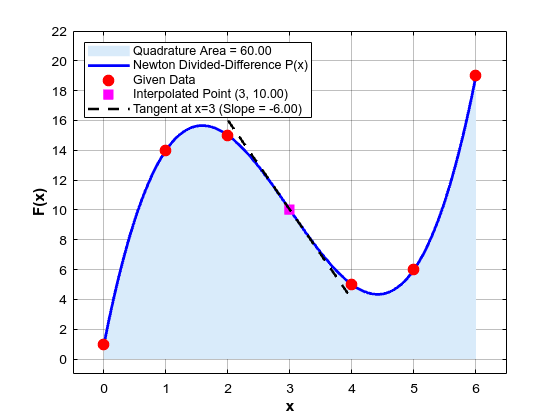

In [4]:
figure('Color', 'w'); hold on; grid on; box on;
set(gca, 'Color', 'w', 'XColor', 'k', 'YColor', 'k');
x_dense = linspace(0, 6, 400); y_dense = P_fun(x_dense);
fill([x_dense, fliplr(x_dense)], [y_dense, zeros(size(y_dense))], ...
    [0.85, 0.92, 0.98], "EdgeColor", "none", ...
    "DisplayName", sprintf("Quadrature Area = %.2f", I_total));
plot(x_dense, y_dense, "b-", "LineWidth", 2, ...
    "DisplayName", "Newton Divided-Difference P(x)");
plot(x_data, y_data, "ro", "MarkerFaceColor", "r", ...
    "MarkerSize", 8, "DisplayName", "Given Data");
plot(3, y_3, "ms", "MarkerFaceColor", "m", "MarkerSize", 9, ...
    "DisplayName", sprintf("Interpolated Point (3, %.2f)", y_3));
x_tan = linspace(2.0, 4.0, 50); y_tan = y_3 + dydx_3 * (x_tan - 3);
plot(x_tan, y_tan, "k--", "LineWidth", 1.8, ...
    "DisplayName", sprintf("Tangent at x=3 (Slope = %.2f)", dydx_3));
xlabel("x", "FontWeight", "bold", "Color", "k");
ylabel("F(x)", "FontWeight", "bold", "Color", "k");
legend('Location', 'northwest', 'TextColor', 'k', ...
    'Box', 'on', 'Color', 'w', 'EdgeColor', 'k');
xlim([-0.5, 6.5]); ylim([min(y_dense) - 2, max(y_dense) + 3]);
hold off;

## Discussion

- **Behaviour of the interpolant.** Six data points technically support a divided-difference polynomial of degree up to five, but the higher-order divided differences ($f[x_0,\dots,x_4]$ and $f[x_0,\dots,x_5]$) vanish, so $P(x)$ reduces to the exact cubic $P(x) = x^3 - 9x^2 + 21x + 1$.
- **Point prediction and local sensitivity.** The missing node evaluates to $P(3) = 10$, and the step-halving central difference converges to $\left.dy/dx\right|_{x=3} = -6$, matching the analytical derivative $P'(x) = 3x^2 - 18x + 21 \Rightarrow P'(3) = -6$.
- **Expected convergence behaviour.** Since the trapezoidal rule's truncation error scales as $O(h^2)$, each halving of the interval width should in principle reduce the error by a factor of $\approx 4$; this is consistent with why several refinement steps are needed to satisfy $\epsilon$-tolerance even for a low-order polynomial.


\newpage

# Question 1 (Day 5, Set 2)

## Problem Statement

Kinetic data obtained using a batch reactor for the hydrolysis of tert-butyl bromide in a solvent of 90% acetone and 10% water are given below. The reaction is

$$
(CH_3)_3CBr + H_2O \rightarrow (CH_3)_3COH + HBr, \quad C_r = C_{(CH_3)_3CBr}
$$

| Time, h | 0 | 3.15 | 4.10 | 6.20 | 8.20 | 10.0 | 13.5 | 18.3 | 26.0 | 30.8 |
|---|---|---|---|---|---|---|---|---|---|---|
| $C_r$ | 0.1039 | 0.0896 | 0.0859 | 0.0776 | 0.0701 | 0.0639 | 0.0529 | 0.0353 | 0.0270 | 0.0207 |

What rate equation is consistent with this data?

*Hint: (i) Interpolate the data at equal intervals of time. (ii) Calculate the derivative numerically. (iii) Use regression analysis (linear and nonlinear).*


## Analysis and Inputs

- The raw measurements are unequally spaced in time, so the concentration data are first re-sampled onto an equally spaced time grid ($t = 0$ to $30$ h, $\Delta t = 2$ h) using piecewise linear interpolation.
- The rate of disappearance, $-dC/dt$, is estimated from the equally spaced data using three-point difference formulas: forward at the first point, central at the interior points, and backward at the last point. The reaction rate is reported as $r = -dC/dt$ so that it is positive.
- Assuming a power-law rate expression $r = kC^n$:
  - **Linear regression** is performed on the linearised form $\ln(r) = \ln(k) + n\ln(C)$, giving the reaction order $n$ as the slope and $\ln(k)$ as the intercept.
  - **Nonlinear regression** is performed directly on $r = kC^n$ using the Gauss-Newton method, starting from the linear-regression estimates of $k$ and $n$.
- Only points with $C > 0$ and $r > 0$ are retained before regression, since $\ln(C)$ and $\ln(r)$ are undefined otherwise.


## Algorithm

- **Step 01.** **START**
- **Step 02.** Inputs:

    | Variable | Description |
    |---|---|
    | $t_{raw}, C_{raw}$ | Raw experimental time and concentration data |
    | $\Delta t$ | Equally spaced grid step size |
    | $k_0, n_0$ | Initial guesses for nonlinear regression |
    | tol, $N_{max}$ | Gauss-Newton convergence tolerance and iteration limit |

- **Step 03.** Build an equally spaced time grid $t_{eq}$ from $t_{min}=0$ to $t_{max}=30$ with step $\Delta t$.
- **Step 04.** For each point on $t_{eq}$, locate the bracketing raw-data interval and estimate $C_{eq}$ by piecewise linear interpolation.
- **Step 05.** Compute $dC/dt$ on the equally spaced grid: 3-point forward difference at the first point, 3-point central difference at interior points, 3-point backward difference at the last point.
- **Step 06.** Compute the rate of disappearance, $r = -dC/dt$, at each grid point.
- **Step 07.** Retain only points where $C_{eq} > 0$ and $r > 0$, stored as $(C_{fit}, R_{fit})$.
- **Step 08.** Linearise $r = kC^n$ as $\ln(r) = \ln(k) + n\ln(C)$, with $x = \ln(C_{fit})$, $y = \ln(R_{fit})$.
- **Step 09.** Perform ordinary least-squares regression of $y$ on $x$ to obtain the slope $n_{lin}$ (reaction order) and intercept $b_{lin} = \ln(k_{lin})$.
- **Step 10.** Compute $R^2_{lin}$ for the linear fit.
- **Step 11.** Repeat until $\sqrt{\Delta k^2 + \Delta n^2} <$ tol or iteration count reaches $N_{max}$:
  - Using $(k_{nl}, n_{nl})$ starting from $(k_{lin}, n_{lin})$, compute the residual $r_i = R_{fit,i} - k_{nl}C_{fit,i}^{n_{nl}}$ and the Jacobian columns $J_1 = -C_{fit,i}^{n_{nl}}$, $J_2 = -k_{nl}C_{fit,i}^{n_{nl}}\ln(C_{fit,i})$
  - Assemble the normal equations $J^TJ\,\Delta = J^Tr$ and solve the $2\times2$ system for $(\Delta k, \Delta n)$
  - Update $k_{nl} \leftarrow k_{nl} + \Delta k$, $n_{nl} \leftarrow n_{nl} + \Delta n$
- **Step 12.** Compute $R^2_{nl}$ for the nonlinear fit.
- **Step 13.** Outputs:

    | Variable | Description |
    |---|---|
    | $n_{lin}, k_{lin}, R^2_{lin}$ | Linear-regression reaction order, rate constant, goodness of fit |
    | $n_{nl}, k_{nl}, R^2_{nl}$ | Nonlinear-regression reaction order, rate constant, goodness of fit |

- **Step 14.** **STOP**


## Implementation

In [21]:
%%file piecewise_interp.m
function C_eq = piecewise_interp(t_raw, C_raw, t_eq) %#ok<FNDEF>
    Nraw = length(t_raw);
    Neq = length(t_eq);
    C_eq = zeros(1, Neq);

    for i = 1:Neq
        tq = t_eq(i);
        for j = 1:Nraw-1
            if tq >= t_raw(j) && tq <= t_raw(j+1)
                C_eq(i) = C_raw(j) + (C_raw(j+1) - C_raw(j)) * ...
                    (tq - t_raw(j)) / (t_raw(j+1) - t_raw(j));
                break;
            end
        end
    end
end


File piecewise_interp.m created successfully.

In [ ]:
%%file threept_derivative.m
function dCdt = threept_derivative(C_eq, dt) %#ok<FNDEF>
    Neq = length(C_eq);
    dCdt = zeros(1, Neq);

    dCdt(1) = (-3*C_eq(1) + 4*C_eq(2) - C_eq(3)) / (2*dt);

    for i = 2:Neq-1
        dCdt(i) = (C_eq(i+1) - C_eq(i-1)) / (2*dt);
    end

    dCdt(Neq) = (3*C_eq(Neq) - 4*C_eq(Neq-1) + C_eq(Neq-2)) / (2*dt);
end


File threept_derivative.m created successfully.

In [ ]:
%%file linear_regress.m
function [slope, intercept, R2] = linear_regress(x, y) %#ok<FNDEF>
    N = length(x);
    Sx = sum(x); Sy = sum(y);
    Sxx = sum(x .* x); Sxy = sum(x .* y);

    slope = (N*Sxy - Sx*Sy) / (N*Sxx - Sx*Sx);
    intercept = (Sy - slope*Sx) / N;

    ybar = Sy / N;
    ypred = intercept + slope*x;
    SSt = sum((y - ybar).^2);
    SSr = sum((y - ypred).^2);
    R2 = 1 - SSr/SSt;
end


File linear_regress.m created successfully.

In [ ]:
%%file gauss_newton_powerlaw.m
function [k, n, R2, iters] = gauss_newton_powerlaw(...
    Cfit, Rfit, k0, n0, tol, k_max) %#ok<FNDEF>
    k = k0; n = n0;
    Nfit = length(Cfit);

    for iters = 1:k_max
        JTJ = zeros(2,2); JTr = zeros(2,1);
        for i = 1:Nfit
            C = Cfit(i);
            predicted = k * C^n;
            residual = Rfit(i) - predicted;
            J1 = -C^n; J2 = -k * C^n * log(C);

            JTJ(1,1) = JTJ(1,1) + J1*J1;
            JTJ(1,2) = JTJ(1,2) + J1*J2;
            JTJ(2,1) = JTJ(2,1) + J2*J1;
            JTJ(2,2) = JTJ(2,2) + J2*J2;
            JTr(1) = JTr(1) + J1*residual;
            JTr(2) = JTr(2) + J2*residual;
        end

        detJ = JTJ(1,1)*JTJ(2,2) - JTJ(1,2)*JTJ(2,1);
        if abs(detJ) < 1e-20; break; end

        delta1 = -(JTJ(2,2)*JTr(1) - JTJ(1,2)*JTr(2)) / detJ;
        delta2 = -(-JTJ(2,1)*JTr(1) + JTJ(1,1)*JTr(2)) / detJ;
        k = k + delta1; n = n + delta2;

        if sqrt(delta1^2 + delta2^2) < tol; break; end
    end

    ratebar = mean(Rfit);
    predicted_all = k * Cfit.^n;
    SSt = sum((Rfit - ratebar).^2);
    SSr = sum((Rfit - predicted_all).^2);
    R2 = 1 - SSr/SSt;
end


File gauss_newton_powerlaw.m created successfully.

In [5]:
fprintf("--- INPUT ---\n");
t_raw = [0 3.15 4.10 6.20 8.20 10.0 13.5 18.3 26.0 30.8];
C_raw = [0.1039 0.0896 0.0859 0.0776 0.0701 ...
         0.0639 0.0529 0.0353 0.0270 0.0207];

dt = 2; tmin = 0; tmax = 30;
Neq = floor((tmax - tmin)/dt) + 1;
t_eq = tmin + (0:Neq-1) * dt;

disp(table(dt, Neq, VariableNames={'dt', 'Neq'}));

C_eq = piecewise_interp(t_raw, C_raw, t_eq);
dCdt = threept_derivative(C_eq, dt);
rate = -dCdt;

valid = (C_eq > 0) & (rate > 0);
Cfit = C_eq(valid);
Rfit = rate(valid);
Nfit = length(Cfit);

x = log(Cfit);
y = log(Rfit);
[n_lin, b_lin, R2_lin] = linear_regress(x, y);

k_lin = exp(b_lin);
tol = 1e-10; k_max = 100;
[k_nl, n_nl, R2_nl, iters] = ...
    gauss_newton_powerlaw(Cfit, Rfit, k_lin, n_lin, tol, k_max);

fprintf("\n--- OUTPUT ---\n");
fprintf("Linear regression (rate = k*C^n):\n\n");
disp(table(n_lin, k_lin, R2_lin, VariableNames={'n', 'k', 'R2'}));

fprintf("Nonlinear regression, Gauss-Newton (rate = k*C^n):\n\n");
disp(table(n_nl, k_nl, R2_nl, iters, ...
    VariableNames={'n', 'k', 'R2', 'iterations'}));


--- INPUT ---
    dt    Neq
    __    ___

    2     16 


--- OUTPUT ---
Linear regression (rate = k*C^n):

      n          k          R2   
    ______    ________    _______

    1.0077    0.052088    0.82296

Nonlinear regression, Gauss-Newton (rate = k*C^n):

       n          k          R2       iterations
    _______    ________    _______    __________

    0.83815    0.032885    0.84467        11    



\newpage

## Visualization

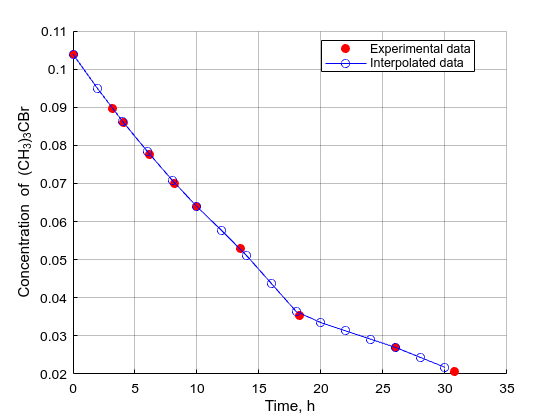

In [30]:
figure('Color', 'w'); hold on; grid on;
set(gca, 'Color', 'w', 'XColor', 'k', 'YColor', 'k');
plot(t_raw, C_raw, "ro", "MarkerFaceColor", "r", ...
    "DisplayName", "Experimental data");
plot(t_eq, C_eq, "bo-", "DisplayName", "Interpolated data");
xlabel("Time, h");
ylabel("Concentration of (CH_3)_3CBr");
legend('Location', "best", 'TextColor', 'k', ...
    'Color', 'w', 'EdgeColor', 'k');
hold off;


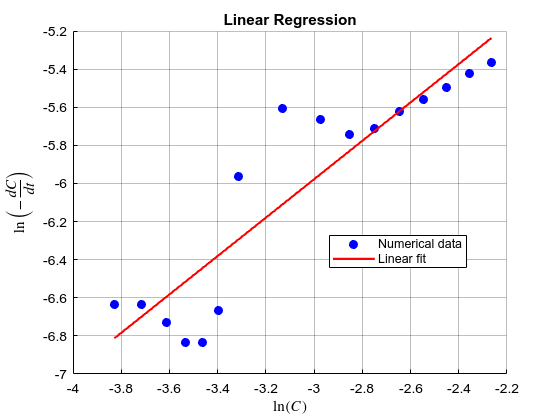

In [7]:
figure('Color', 'w'); hold on; grid on;
set(gca, 'Color', 'w', 'XColor', 'k', 'YColor', 'k');
plot(x, y, "bo", "MarkerFaceColor", "b", ...
    "DisplayName", "Numerical data");
xx = linspace(min(x), max(x), 50);
yy = b_lin + n_lin * xx;
plot(xx, yy, "r-", "LineWidth", 1.5, "DisplayName", "Linear fit");
xlabel('$\ln(C)$', 'Interpreter', 'latex');
ylabel('$\ln\left(-\frac{dC}{dt}\right)$', 'Interpreter', 'latex');
title("Linear Regression", 'Color', 'k');
legend('Location', "best", 'TextColor', 'k', ...
    'Color', 'w', 'EdgeColor', 'k');
hold off;


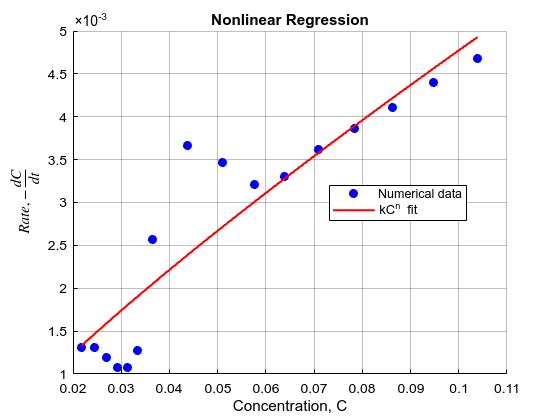

In [6]:
figure('Color', 'w'); hold on; grid on;
set(gca, 'Color', 'w', 'XColor', 'k', 'YColor', 'k');
plot(Cfit, Rfit, "bo", "MarkerFaceColor", "b", ...
    "DisplayName", "Numerical data");
Cx = linspace(min(Cfit), max(Cfit), 50);
Ry = k_nl * Cx.^n_nl;
plot(Cx, Ry, "r-", "LineWidth", 1.5, "DisplayName", "kC^n fit");
xlabel("Concentration, C");
ylabel("$Rate, -\frac{dC}{dt}$", 'Interpreter', 'latex');
title("Nonlinear Regression", "Color", 'k');
legend('Location', "best", 'TextColor', 'k', ...
    'Color', 'w', 'EdgeColor', 'k');
hold off;


\newpage

## Discussion

- The raw concentration-time data are unequally spaced, so piecewise linear interpolation onto a $\Delta t = 2$ h grid was needed before a uniform-step differentiation formula could be applied.
- The rate of disappearance $r = -dC/dt$ was obtained with a forward difference at the first point, central differences at interior points, and a backward difference at the last point, all evaluated on the equally spaced grid.
- Linearising the assumed rate law $r = kC^n$ to $\ln(r) = \ln(k) + n\ln(C)$ and fitting by ordinary least squares gives $n_{lin} \approx 1.008$ and $k_{lin} \approx 0.0521$, with $R^2_{lin} \approx 0.823$ — reaction order close to unity.
- Refining the same power-law model directly (without linearisation) by Gauss-Newton gives $n_{nl} \approx 0.838$ and $k_{nl} \approx 0.0329$, converging in 11 iterations with a slightly better fit, $R^2_{nl} \approx 0.845$.
- Both regressions agree in order of magnitude and point toward kinetics close to first order in $(CH_3)_3CBr$. The modest spread between the two estimates reflects the sensitivity of numerically differentiated rate values to the fitting procedure (linearised vs. direct nonlinear fit) rather than a disagreement in the underlying chemistry.
